# 07 — Final results on the test set
The best setup is selected on validation and the **test set is evaluated only once**. This number estimates performance on data the model has never seen.

In [1]:
# On Colab: mount Drive and work from the project's notebooks folder
import os, sys
if "google.colab" in sys.modules and not os.getcwd().endswith("notebooks"):
    from google.colab import drive
    drive.mount("/content/drive")
    %cd /content/drive/MyDrive/bone-age/notebooks
%run 00_common.ipynb

In [2]:
experiments = pd.read_json(OUTPUT_DIR / "experiments.json")
best = experiments.iloc[0]
print(f"Selected on validation: {best['setup']} (val MAE {best['val_mae']:.2f})")
res, metrics = evaluate(best["runs"], "test", bool(best["tta"]))
out_dir = OUTPUT_DIR / "test_results"
out_dir.mkdir(exist_ok=True)
res.to_csv(out_dir / "predictions.csv", index=False)
(out_dir / "metrics.json").write_text(json.dumps({"setup": best["setup"], **metrics}, indent=2))
print(f"TEST  MAE {metrics['mae']:.2f} mo | RMSE {metrics['rmse']:.2f} mo | R2 {metrics['r2']:.4f}")

Selected on validation: baseline_b0_384 + b0_512 + b3_384 + TTA (val MAE 6.26)


predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

predict:   0%|          | 0/40 [00:00<?, ?it/s]

TEST  MAE 6.54 mo | RMSE 8.80 mo | R2 0.9530


In [3]:
base = pd.read_csv(OUTPUT_DIR / "baselines.csv").set_index("split")
pd.DataFrame({"Test MAE (months)": {
    "Baseline: train mean": base.loc["test", "mean_baseline_mae"],
    "Baseline: mean per sex": base.loc["test", "sex_mean_baseline_mae"],
    f"Ours: {best['setup']}": metrics["mae"],
    "RSNA 2017 winner (official test set)": 4.27,
}}).round(2)

,Test MAE (months)
Baseline: train mean,33.28
Baseline: mean per sex,31.98
Ours: baseline_b0_384 + b0_512 + b3_384 + TTA,6.54
RSNA 2017 winner (official test set),4.27


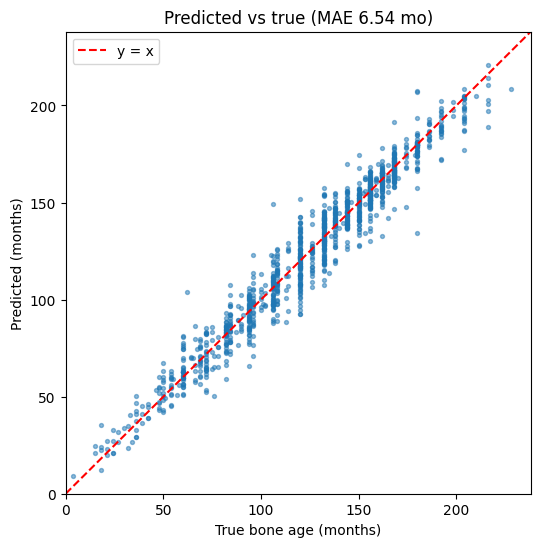

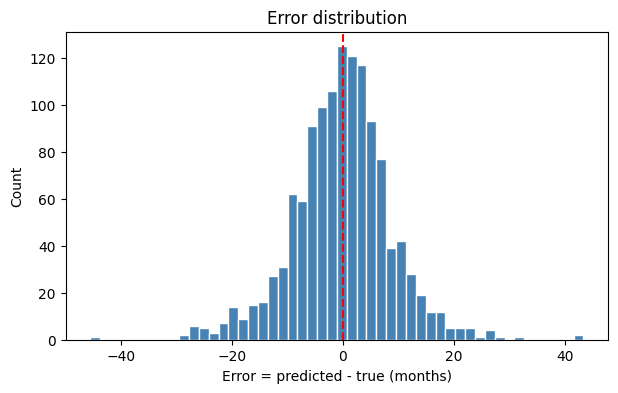

In [4]:
plot_results(res, out_dir)

In [5]:
by_age = res.groupby("age_group", observed=True)["abs_error"].agg(MAE="mean", n="size")
by_sex = res.groupby(res["male"].map({True: "male", False: "female"}))["abs_error"].agg(MAE="mean", n="size")
display(by_age.round(2), by_sex.round(2))

,MAE,n
age_group,,
0-5y,5.52,72
5-10y,7.11,357
10-15y,6.35,725
15+y,6.63,108


,MAE,n
male,,
female,6.81,579
male,6.32,683


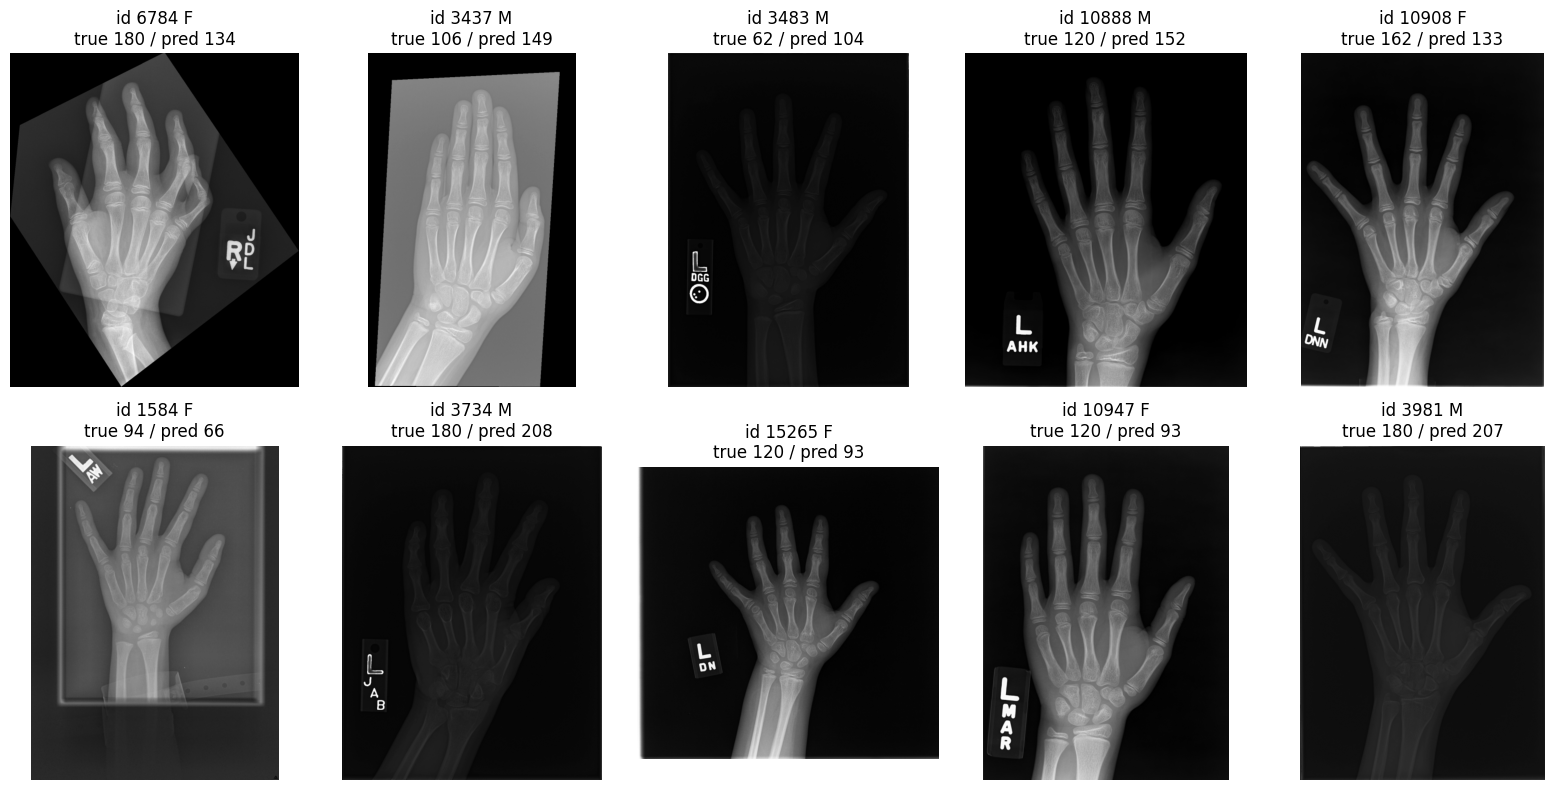

,id,male,boneage,pred,error
432,6784,False,180,134.500000,-45.5
173,3437,True,106,149.399994,43.4
176,3483,True,62,104.099998,42.1
802,10888,True,120,151.800003,31.8
805,10908,False,162,133.000000,-29.0
17,1584,False,94,65.699997,-28.3
196,3734,True,180,207.500000,27.5
1224,15265,False,120,92.599998,-27.4
811,10947,False,120,92.699997,-27.3
220,3981,True,180,207.199997,27.2


In [6]:
worst = show_worst(res, out_dir)
worst[["id", "male", "boneage", "pred", "error"]].round(1)

## Best 10 predictions

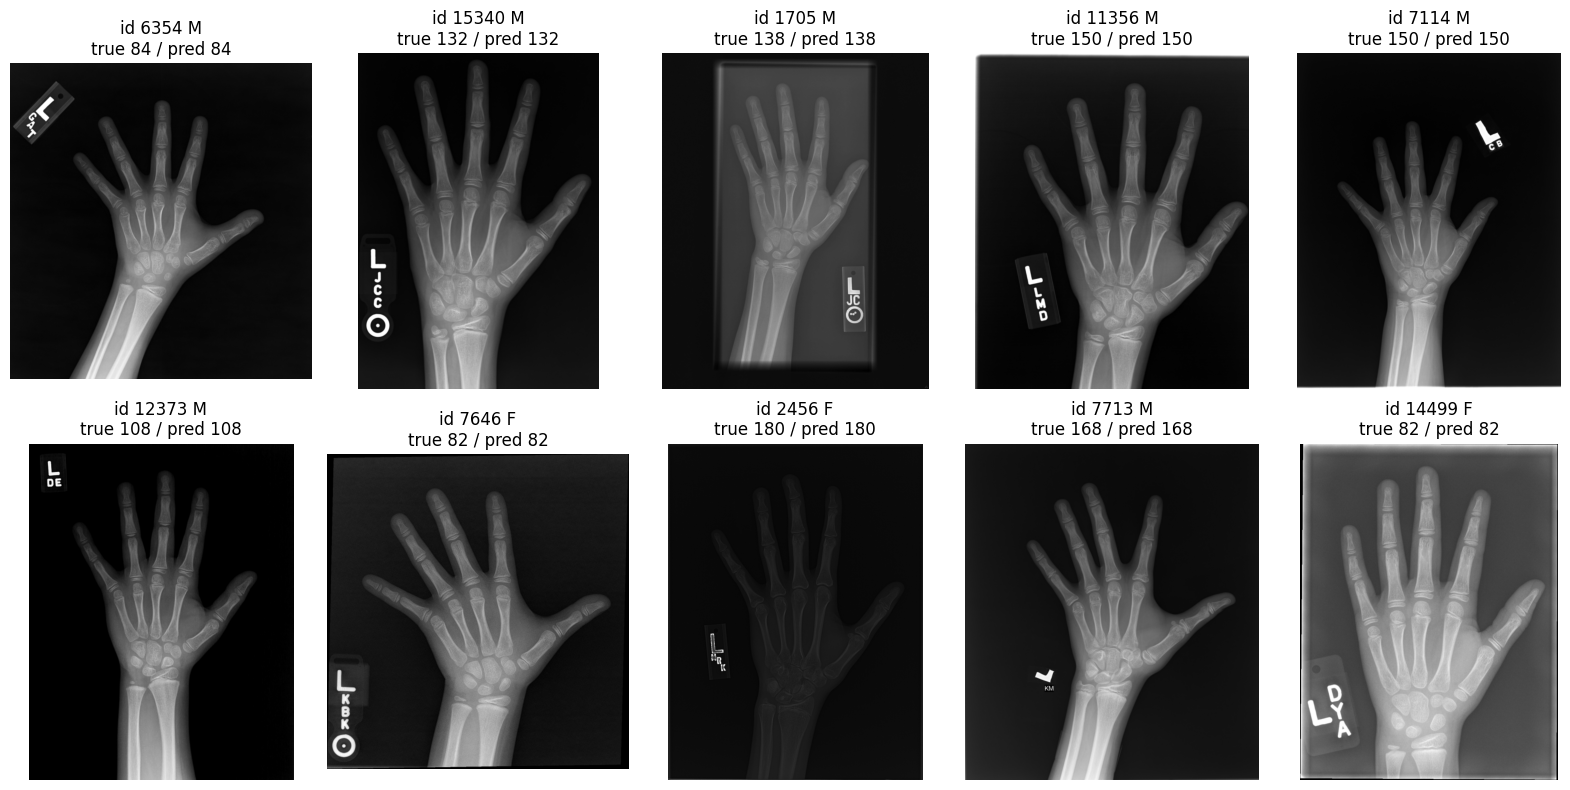

,id,male,boneage,pred,error
396,6354,True,84,84.0,0.0
1235,15340,True,132,132.0,0.0
27,1705,True,138,138.0,0.0
847,11356,True,150,150.0,-0.0
456,7114,True,150,150.0,-0.0
949,12373,True,108,108.0,-0.0
518,7646,False,82,82.0,-0.0
89,2456,False,180,180.0,-0.0
521,7713,True,168,168.0,-0.0
1152,14499,False,82,82.0,-0.0


In [ ]:
best_preds = show_best(res, out_dir)
best_preds[["id", "male", "boneage", "pred", "error"]].round(1)

## Best results
A summary of saved results: the top 5 setups on validation and each model's best epoch. A test result exists only for the selected setup; the other setups were not evaluated on the test set.

In [ ]:
# Saved results only: nothing is predicted here, so the test set is not evaluated again
val = pd.read_json(OUTPUT_DIR / "experiments.json")
test = json.loads((OUTPUT_DIR / "test_results" / "metrics.json").read_text())

best_epochs = pd.DataFrame([
    {"model": run, "best epoch": log.loc[log["val_mae_months"].idxmin(), "epoch"], "epochs run": len(log),
     "best val MAE": log["val_mae_months"].min()}
    for run in ["baseline_b0_384", "b0_512", "b3_384", "scratch_cnn_cls"]
    for log in [pd.read_csv(OUTPUT_DIR / run / "log.csv")]
]).sort_values("best val MAE")

print(f"Best setup: {test['setup']}")
print(f"Validation MAE {val.iloc[0]['val_mae']:.2f} mo | Test MAE {test['mae']:.2f} mo | "
      f"Test RMSE {test['rmse']:.2f} mo | Test R2 {test['r2']:.4f}")
display(val[["setup", "val_mae", "val_rmse", "val_r2"]].head(5).round(3), best_epochs.round(2))

Best setup: baseline_b0_384 + b0_512 + b3_384 + TTA
Validation MAE 6.26 mo | Test MAE 6.54 mo | Test RMSE 8.80 mo | Test R2 0.9530


,setup,val_mae,val_rmse,val_r2
0,baseline_b0_384 + b0_512 + b3_384 + TTA,6.255,8.207,0.961
1,baseline_b0_384 + b0_512 + b3_384,6.300,8.269,0.960
2,baseline_b0_384 + TTA,6.549,8.528,0.958
3,b0_512 + TTA,6.616,8.602,0.957
4,baseline_b0_384,6.674,8.702,0.956


,model,best epoch,epochs run,best val MAE
0,baseline_b0_384,24,29,6.67
1,b0_512,15,20,6.72
2,b3_384,12,17,7.09
3,scratch_cnn_cls,30,30,7.81


## Findings
- **Test MAE is 6.54 months** (RMSE 8.80, R² 0.953). This is close to the validation value of 6.26, so model selection does not appear to have overfit validation badly. It is about 5 times better than the baseline (33.3), close to the "good result" target (< 6 months), and about 2.3 months behind the challenge winner (4.27, on the official test set, so not directly comparable).
- **Scatter:** Predictions lie in a narrow band around y=x. The vertical "columns" come from labels being concentrated on multiples of 6 and 12 months, as seen in the EDA.
- **Age group:** MAE is lowest for 0–5 years (5.5 months, only 72 images) and highest for 5–10 years (7.1 months). The cause of this difference was not investigated.
- **Sex:** MAE is 6.81 months for females and 6.32 for males, a small difference whose cause was not investigated.

**Worst 10 predictions, by visual inspection:**
1. **Very dark or low-contrast images** (ids 3483, 3734, 3981): Bone detail is barely visible. Darkness alone does not explain the error, though: id 2456 is also very dark and is among the best predictions. Applying CLAHE or histogram equalization to every image, not only as augmentation, is worth trying.
2. **Unusual position or hand shape** (id 6784): The hand is rotated well beyond the ±15° augmentation range, the fingers are bent, and an "R" marker is visible.
3. **Scanned film or washed-out grey** (ids 1584, 3437): The hand sits inside a grey frame or is cropped, and contrast is low.
4. **Images that look normal** (ids 10888, 10908, 10947): Quality is good, yet errors are 27–32 months. Possible causes are label noise or atypical development; this data cannot distinguish between them.